# C-MAPSS – Remaining Useful Life Prediction

In this notebook, I'll load the C-MAPSS data, explore it, create a few useful sensor features, and compare traditional ML models with PyTorch models.

I'll use:
- Random Forest and XGBoost for tabular data.
- A PyTorch MLP for tabular data.
- A PyTorch GRU for sensor sequences.

The training RUL column is created from the training data. The official test RUL labels are used only for the final evaluation.

**Before running:** check the dataset path in the next section. This notebook is written for the FD001 subset, but the subset name can be changed.

## 1. Imports

In [1]:
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Load the dataset

I kept the folder used in my original notebook. Change `data_dir` if the files are stored somewhere else.

The folder should contain:
- `train_FD001.txt`
- `test_FD001.txt`
- `RUL_FD001.txt`

In [2]:
subset = "FD001"
data_dir = Path(r"D:\ML_project\extracted\CMaps")

columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

read_options = {
    "sep": r"\s+",
    "header": None,
    "names": columns
}

train_path = data_dir / f"train_{subset}.txt"
test_path = data_dir / f"test_{subset}.txt"
rul_path = data_dir / f"RUL_{subset}.txt"

for file_path in [train_path, test_path, rul_path]:
    if not file_path.exists():
        raise FileNotFoundError(
            f"Could not find {file_path}. Check the data_dir and subset name."
        )

train_df = pd.read_csv(train_path, **read_options)
test_df = pd.read_csv(test_path, **read_options)

rul_df = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Test RUL shape:", rul_df.shape)

Training shape: (20631, 26)
Test shape: (13096, 26)
Test RUL shape: (100, 1)


## 3. Take a look at the data

In [3]:
display(train_df.head())
display(test_df.head())
display(rul_df.head())

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


,RUL
0,112
1,98
2,69
3,82
4,91


In [4]:
print("Training data information:")
train_df.info()

print("\nMissing values in training data:")
print(train_df.isnull().sum().sum())

print("\nDuplicate training rows:", train_df.duplicated().sum())

Training data information:
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   unit          20631 non-null  int64  
 1   cycle         20631 non-null  int64  
 2   op_setting_1  20631 non-null  float64
 3   op_setting_2  20631 non-null  float64
 4   op_setting_3  20631 non-null  float64
 5   sensor_1      20631 non-null  float64
 6   sensor_2      20631 non-null  float64
 7   sensor_3      20631 non-null  float64
 8   sensor_4      20631 non-null  float64
 9   sensor_5      20631 non-null  float64
 10  sensor_6      20631 non-null  float64
 11  sensor_7      20631 non-null  float64
 12  sensor_8      20631 non-null  float64
 13  sensor_9      20631 non-null  float64
 14  sensor_10     20631 non-null  float64
 15  sensor_11     20631 non-null  float64
 16  sensor_12     20631 non-null  float64
 17  sensor_13     20631 non-null  float64
 18  sensor_14 

## 4. Create the training RUL column

For each engine, I find its last recorded cycle. Then I subtract the current cycle from that value.

`unit` is used to identify each engine. It won't be used as a model feature.

In [5]:
last_cycle = train_df.groupby("unit")["cycle"].max()

train_df["RUL"] = (
    train_df["unit"].map(last_cycle) - train_df["cycle"]
)

display(train_df[["unit", "cycle", "RUL"]].head(10))
print("Maximum training RUL:", train_df["RUL"].max())

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


Maximum training RUL: 361


## 5. Quick EDA

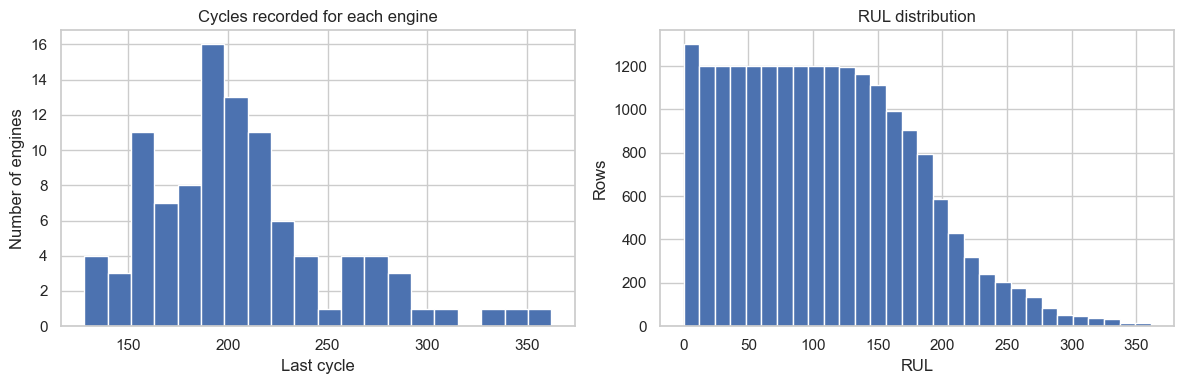

In [6]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_cycles = train_df.groupby("unit")["cycle"].max()

axes[0].hist(train_cycles, bins=20)
axes[0].set_title("Cycles recorded for each engine")
axes[0].set_xlabel("Last cycle")
axes[0].set_ylabel("Number of engines")

axes[1].hist(train_df["RUL"], bins=30)
axes[1].set_title("RUL distribution")
axes[1].set_xlabel("RUL")
axes[1].set_ylabel("Rows")

plt.tight_layout()
plt.show()

In [7]:
sensor_columns = [
    col for col in train_df.columns
    if col.startswith("sensor_") and col.split("_")[-1].isdigit()
]

setting_columns = [
    col for col in train_df.columns
    if col.startswith("op_setting_") and col.split("_")[-1].isdigit()
]

original_features = ["cycle"] + setting_columns + sensor_columns

print("Number of sensors:", len(sensor_columns))
print("Number of settings:", len(setting_columns))
print("Number of original features:", len(original_features))

display(train_df[original_features + ["RUL"]].describe().T)

Number of sensors: 21
Number of settings: 3
Number of original features: 25


,count,mean,std,min,25%,50%,75%,max
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
op_setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
op_setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
op_setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100


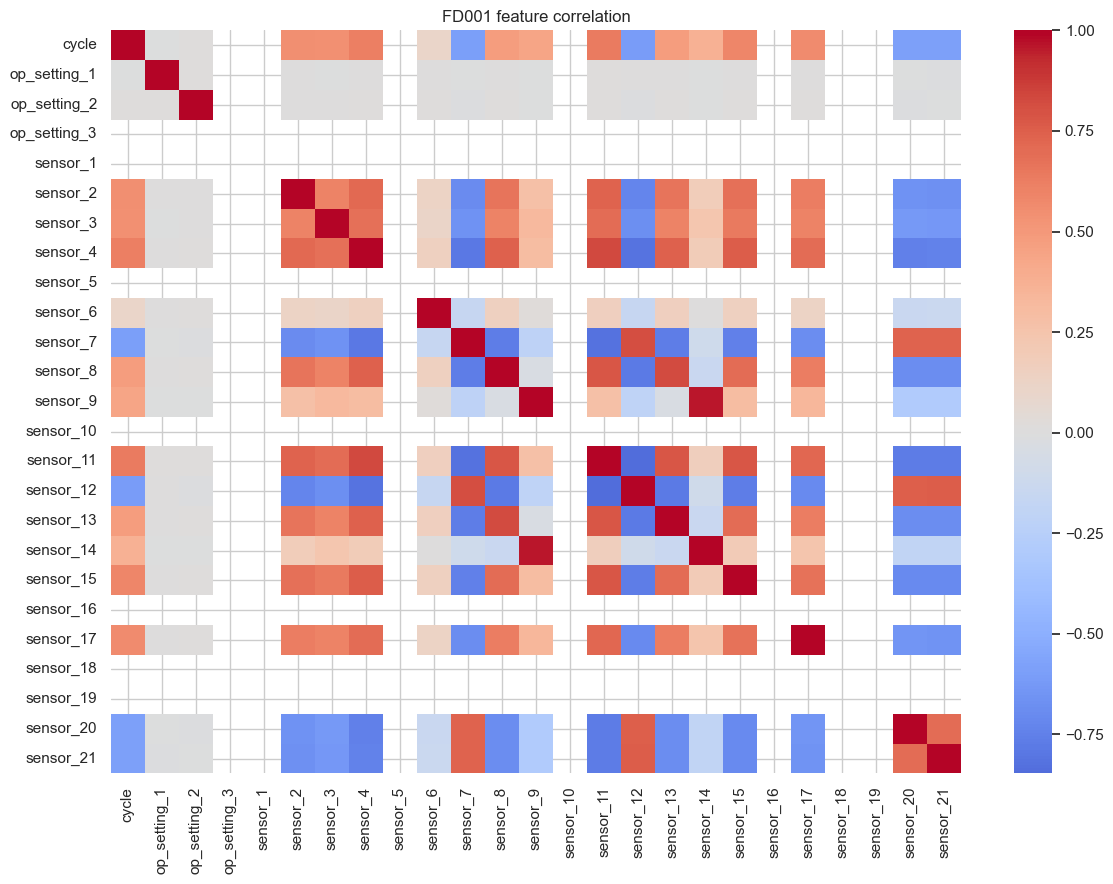

In [8]:
plt.figure(figsize=(12, 9))
sns.heatmap(train_df[original_features].corr(), cmap="coolwarm", center=0)
plt.title(f"{subset} feature correlation")
plt.tight_layout()
plt.show()

## 6. Create extra sensor features

I'll keep the original sensor columns and add a few more columns from them.

- **Rolling mean:** recent average over the last five cycles.
- **Rolling standard deviation:** recent variation in the sensor.
- **Difference:** change from the previous cycle.
- **Lag 1 and Lag 3:** sensor values from earlier cycles.
- **EWMA:** moving average that gives more weight to recent readings.

I group by `unit` so values from different engines never get mixed. The calculations use the current cycle and earlier cycles only.

In [9]:
def add_sensor_features(data):
    data = data.sort_values(["unit", "cycle"]).copy()

    for col in sensor_columns:
        sensor = data.groupby("unit")[col]

        data[f"{col}_rolling_mean_5"] = sensor.transform(
            lambda x: x.rolling(5, min_periods=1).mean()
        )

        data[f"{col}_rolling_std_5"] = sensor.transform(
            lambda x: x.rolling(5, min_periods=2).std()
        )

        data[f"{col}_diff_1"] = sensor.diff()
        data[f"{col}_lag_1"] = sensor.shift(1)
        data[f"{col}_lag_3"] = sensor.shift(3)

        data[f"{col}_ewma_5"] = sensor.transform(
            lambda x: x.ewm(span=5, adjust=False).mean()
        )

    return data


train_features = add_sensor_features(train_df)
test_features = add_sensor_features(test_df)

print("Training shape after feature engineering:", train_features.shape)
print("Test shape after feature engineering:", test_features.shape)

C:\Users\Adi\AppData\Local\Temp\ipykernel_91960\2487025910.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{col}_diff_1"] = sensor.diff()
C:\Users\Adi\AppData\Local\Temp\ipykernel_91960\2487025910.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{col}_lag_1"] = sensor.shift(1)
C:\Users\Adi\AppData\Local\Temp\ipykernel_91960\2487025910.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all

Training shape after feature engineering: (20631, 153)
Test shape after feature engineering: (13096, 152)


C:\Users\Adi\AppData\Local\Temp\ipykernel_91960\2487025910.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{col}_diff_1"] = sensor.diff()
C:\Users\Adi\AppData\Local\Temp\ipykernel_91960\2487025910.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{col}_lag_1"] = sensor.shift(1)
C:\Users\Adi\AppData\Local\Temp\ipykernel_91960\2487025910.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all

## 7. Prepare the test labels

The test file contains only the last few recorded cycles for each engine. The separate RUL file gives the remaining life at the final recorded cycle.

I'll use that to calculate the RUL for each test row, then keep only the last row of each engine for the final evaluation.

In [10]:
test_units = sorted(test_features["unit"].unique())
test_final_rul = rul_df["RUL"].to_numpy()

if len(test_units) != len(test_final_rul):
    raise ValueError("The number of test engines and RUL labels does not match.")

test_last_cycle = test_features.groupby("unit")["cycle"].max()
test_rul_by_unit = pd.Series(test_final_rul, index=test_units)

test_features["RUL"] = (
    test_features["unit"].map(test_last_cycle)
    + test_features["unit"].map(test_rul_by_unit)
    - test_features["cycle"]
)

test_last_rows = (
    test_features.sort_values(["unit", "cycle"])
    .groupby("unit")
    .tail(1)
    .sort_values("unit")
    .reset_index(drop=True)
)

print("Number of test engines:", len(test_last_rows))
display(test_last_rows[["unit", "cycle", "RUL"]].head())

Number of test engines: 100


C:\Users\Adi\AppData\Local\Temp\ipykernel_91960\1369940221.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test_features["RUL"] = (


,unit,cycle,RUL
0,1,31,112
1,2,49,98
2,3,126,69
3,4,106,82
4,5,98,91


## 8. Make a validation split by engine

I don't want rows from one engine to appear in both training and validation. I'll split by `unit`.

For validation, I'll check the last recorded cycle of each validation engine. This is closer to how the official test labels are provided.

In [11]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_features,
        train_features["RUL"],
        groups=train_features["unit"]
    )
)

sequence_length = 30  # GRU will use the latest 30 cycles.

train_units = train_features.iloc[train_idx]["unit"].unique()
val_units = train_features.iloc[val_idx]["unit"].unique()

train_part = train_features[
    train_features["unit"].isin(train_units)
].copy()

# Validation engines are cut off before failure, like the official test engines.
rng = np.random.default_rng(42)

val_rows = []
val_prefixes = []

for unit in val_units:
    engine = (
        train_features[train_features["unit"] == unit]
        .sort_values("cycle")
        .copy()
    )

    last_cycle = int(engine["cycle"].max())

    # Choose a cutoff before the engine's final cycle.
    first_cutoff = max(sequence_length, int(0.7 * last_cycle))
    cutoff = int(rng.integers(first_cutoff, last_cycle))

    # This is the final observation available to the model.
    val_row = engine[engine["cycle"] == cutoff].iloc[-1]
    val_rows.append(val_row)

    # GRU sees only the engine history up to this cutoff.
    val_prefixes.append(engine[engine["cycle"] <= cutoff])

val_rows = pd.DataFrame(val_rows).reset_index(drop=True)
val_prefix_data = pd.concat(val_prefixes, ignore_index=True)

# All validation targets must be positive because we stop before failure.
if (val_rows["RUL"] <= 0).any():
    raise ValueError("Validation cutoffs must be before the failure cycle.")

print("Training engines:", len(train_units))
print("Validation engines:", len(val_units))
print("Engine overlap:", len(set(train_units).intersection(set(val_units))))
print("\nValidation RUL distribution:")
display(val_rows["RUL"].describe())

print("Validation rows:", len(val_rows))
print("Validation prefix rows for GRU:", len(val_prefix_data))

Training engines: 80
Validation engines: 20
Engine overlap: 0

Validation RUL distribution:


count    20.000000
mean     28.300000
std      18.402231
min       2.000000
25%      15.750000
50%      23.000000
75%      38.250000
max      65.000000
Name: RUL, dtype: float64

Validation rows: 20
Validation prefix rows for GRU: 3504


## 9. Define the feature experiments

Each experiment starts with the original features. Then I'll add one group of engineered features at a time.

The number of added columns depends on how many sensor columns are in the dataset.

In [12]:
feature_groups = {
    "Rolling Mean": ["rolling_mean_5"],
    "Rolling STD": ["rolling_std_5"],
    "Difference": ["diff_1"],
    "Lags": ["lag_1", "lag_3"],
    "EWMA": ["ewma_5"]
}

experiments = {
    "Original": [],
    "Original + Rolling Mean": ["Rolling Mean"],
    "Add Rolling STD": ["Rolling Mean", "Rolling STD"],
    "Add Difference": ["Rolling Mean", "Rolling STD", "Difference"],
    "Add Lags": ["Rolling Mean", "Rolling STD", "Difference", "Lags"],
    "Add EWMA": ["Rolling Mean", "Rolling STD", "Difference", "Lags", "EWMA"]
}

experiment_features = {}

for name, groups in experiments.items():
    extra_features = [
        f"{sensor}_{suffix}"
        for group in groups
        for suffix in feature_groups[group]
        for sensor in sensor_columns
    ]

    experiment_features[name] = original_features + extra_features

for name, selected_features in experiment_features.items():
    print(name, ":", len(selected_features), "features")

Original : 25 features
Original + Rolling Mean : 46 features
Add Rolling STD : 67 features
Add Difference : 88 features
Add Lags : 130 features
Add EWMA : 151 features


## 10. Evaluation metrics

In [13]:
def nasa_score(actual, predicted):
    error = np.asarray(predicted) - np.asarray(actual)

    score = np.where(
        error < 0,
        np.exp(-error / 13) - 1,
        np.exp(error / 10) - 1
    )

    return score.sum()


def evaluate_model(actual, predicted):
    predicted = np.maximum(np.asarray(predicted), 0)

    return {
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "NASA Score": nasa_score(actual, predicted)
    }

## 11. Train Random Forest and XGBoost

These are tree-based models, so I don't need to scale their input features. I will use median imputation because lag and rolling features can contain missing values at the start of an engine's sequence.

The imputer is inside the pipeline, so it learns its values from the training engines only.

In [14]:
models = {
    "Random Forest": lambda: RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

if XGBRegressor is not None:
    models["XGBoost"] = lambda: XGBRegressor(
        n_estimators=250,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
else:
    print("XGBoost is not installed. I'll run Random Forest only.")

In [15]:
ml_results = []
ml_pipelines = {}

for experiment_name, selected_features in experiment_features.items():

    X_train = train_part[selected_features]
    y_train = train_part["RUL"]

    X_val = val_rows[selected_features]
    y_val = val_rows["RUL"]

    for model_name, model_function in models.items():

        model = make_pipeline(
            SimpleImputer(strategy="median"),
            model_function()
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        scores = evaluate_model(y_val, predictions)

        ml_results.append({
            "Model": model_name,
            "Feature Set": experiment_name,
            "Feature Count": len(selected_features),
            **scores
        })

        ml_pipelines[(model_name, experiment_name)] = model


ml_results_df = pd.DataFrame(ml_results)
ml_results_df = ml_results_df.sort_values(
    ["RMSE", "MAE", "NASA Score"]
).reset_index(drop=True)

display(ml_results_df.round(3))

,Model,Feature Set,Feature Count,RMSE,MAE,NASA Score
0,Random Forest,Original,25,15.940,10.381,184.838
1,XGBoost,Original + Rolling Mean,46,16.072,10.126,155.509
2,XGBoost,Original,25,16.740,11.509,222.648
3,XGBoost,Add Rolling STD,67,17.270,10.680,272.511
4,XGBoost,Add Lags,130,17.519,10.654,256.741
5,XGBoost,Add EWMA,151,18.206,11.297,258.522
6,Random Forest,Original + Rolling Mean,46,18.262,10.917,430.675
7,XGBoost,Add Difference,88,18.856,11.318,398.003
8,Random Forest,Add Rolling STD,67,19.446,11.527,523.693
9,Random Forest,Add Difference,88,19.475,11.777,498.950


## 12. Check whether the extra features helped

I'll compare each experiment with the one before it. A lower RMSE, MAE, or NASA score means that metric improved.

In [16]:
improvement_rows = []

for model_name in ml_results_df["Model"].unique():
    model_results = (
        ml_results_df[ml_results_df["Model"] == model_name]
        .set_index("Feature Set")
    )

    experiment_names = list(experiments.keys())

    for previous_name, current_name in zip(
        experiment_names, experiment_names[1:]
    ):
        previous = model_results.loc[previous_name]
        current = model_results.loc[current_name]

        improvement_rows.append({
            "Model": model_name,
            "Added feature group": experiments[current_name][-1],
            "Compared with": previous_name,
            "RMSE improved": current["RMSE"] < previous["RMSE"],
            "MAE improved": current["MAE"] < previous["MAE"],
            "NASA score improved": current["NASA Score"] < previous["NASA Score"]
        })

improvement_df = pd.DataFrame(improvement_rows)
display(improvement_df)

,Model,Added feature group,Compared with,RMSE improved,MAE improved,NASA score improved
0,Random Forest,Rolling Mean,Original,False,False,False
1,Random Forest,Rolling STD,Original + Rolling Mean,False,False,False
2,Random Forest,Difference,Add Rolling STD,False,False,True
3,Random Forest,Lags,Add Difference,False,True,True
4,Random Forest,EWMA,Add Lags,False,False,False
5,XGBoost,Rolling Mean,Original,True,True,True
6,XGBoost,Rolling STD,Original + Rolling Mean,False,False,False
7,XGBoost,Difference,Add Rolling STD,False,False,False
8,XGBoost,Lags,Add Difference,True,True,True
9,XGBoost,EWMA,Add Lags,False,False,False


## 13. PyTorch – MLP for tabular features

An MLP takes one row of features at a time. I'll use the best feature set from the Random Forest / XGBoost experiments.

The numeric features are imputed and standardized. Both transformations are fitted using training engines only.

In [17]:
best_ml_result = ml_results_df.iloc[0]

best_ml_model_name = best_ml_result["Model"]
best_ml_feature_set = best_ml_result["Feature Set"]
mlp_features = experiment_features[best_ml_feature_set]

print("Feature set for the MLP:", best_ml_feature_set)
print("Number of features:", len(mlp_features))

Feature set for the MLP: Original
Number of features: 25


In [18]:
# Prepare the MLP inputs.
mlp_imputer = SimpleImputer(strategy="median")
mlp_scaler = StandardScaler()

X_mlp_train = mlp_imputer.fit_transform(train_part[mlp_features])
X_mlp_train = mlp_scaler.fit_transform(X_mlp_train)

X_mlp_val = mlp_imputer.transform(val_rows[mlp_features])
X_mlp_val = mlp_scaler.transform(X_mlp_val)

y_mlp_train = train_part["RUL"].to_numpy(dtype=np.float32)
y_mlp_val = val_rows["RUL"].to_numpy(dtype=np.float32)

y_mlp_mean = y_mlp_train.mean()
y_mlp_std = y_mlp_train.std() + 1e-8

y_mlp_train_scaled = (y_mlp_train - y_mlp_mean) / y_mlp_std

In [19]:
class MLPRegressor(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


X_train_tensor = torch.tensor(X_mlp_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_mlp_train_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_mlp_val, dtype=torch.float32).to(device)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=128,
    shuffle=True
)

mlp_model = MLPRegressor(X_mlp_train.shape[1]).to(device)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.001)
loss_function = nn.SmoothL1Loss()

best_mlp_loss = float("inf")
best_mlp_state = None
best_mlp_epoch = 0
patience = 8
wait = 0

for epoch in range(1, 61):
    mlp_model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        predictions = mlp_model(batch_X)
        loss = loss_function(predictions, batch_y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    mlp_model.eval()
    with torch.no_grad():
        val_scaled_predictions = mlp_model(X_val_tensor).cpu().numpy()

    val_predictions = val_scaled_predictions * y_mlp_std + y_mlp_mean
    val_rmse = np.sqrt(mean_squared_error(y_mlp_val, val_predictions))

    if val_rmse < best_mlp_loss:
        best_mlp_loss = val_rmse
        best_mlp_epoch = epoch
        best_mlp_state = copy.deepcopy(mlp_model.state_dict())
        wait = 0
    else:
        wait += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d} | "
            f"Training loss: {total_loss / len(train_loader):.4f} | "
            f"Validation RMSE: {val_rmse:.3f}"
        )

    if wait >= patience:
        print("Early stopping.")
        break

mlp_model.load_state_dict(best_mlp_state)
mlp_model.eval()

with torch.no_grad():
    mlp_val_predictions = (
        mlp_model(X_val_tensor).cpu().numpy() * y_mlp_std + y_mlp_mean
    )

mlp_scores = evaluate_model(y_mlp_val, mlp_val_predictions)
print("MLP validation results:")
display(pd.DataFrame([mlp_scores]).round(3))
print("Best epoch:", best_mlp_epoch)

Epoch 01 | Training loss: 0.1766 | Validation RMSE: 19.945
Epoch 05 | Training loss: 0.1378 | Validation RMSE: 17.196
Epoch 10 | Training loss: 0.1334 | Validation RMSE: 17.656
Early stopping.
MLP validation results:


,RMSE,MAE,NASA Score
0,15.616,11.866,103.538002


Best epoch: 3


## 14. PyTorch – GRU for sensor sequences

The MLP sees one row at a time. A GRU sees a sequence of consecutive cycles from the same engine.

For example, with a window size of 30, the GRU receives the last 30 cycles and predicts the RUL at the final cycle in that window.

I'll use the original sensor and operational-setting features for the GRU. Sequence models can learn trends from the order of the readings, so I don't need to add the rolling and lag features again here.

In [20]:
sequence_features = original_features
sequence_length = 30

print("Sequence length:", sequence_length)
print("Features at each cycle:", len(sequence_features))

Sequence length: 30
Features at each cycle: 25


In [21]:
def make_sequences(data, selected_units, feature_columns, sequence_length, last_only=False):
    X = []
    y = []

    for unit in selected_units:
        engine = (
            data[data["unit"] == unit]
            .sort_values("cycle")
            .reset_index(drop=True)
        )

        values = engine[feature_columns].to_numpy(dtype=np.float32)
        targets = engine["RUL"].to_numpy(dtype=np.float32)

        if len(engine) < sequence_length:
            continue

        if last_only:
            X.append(values[-sequence_length:])
            y.append(targets[-1])
        else:
            for end in range(sequence_length - 1, len(engine)):
                X.append(values[end - sequence_length + 1:end + 1])
                y.append(targets[end])

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)


X_gru_train, y_gru_train = make_sequences(
    train_features,
    train_units,
    sequence_features,
    sequence_length
)

X_gru_val, y_gru_val = make_sequences(
    val_prefix_data,
    val_units,
    sequence_features,
    sequence_length,
    last_only=True
)

print("Training sequences:", X_gru_train.shape)
print("Validation sequences:", X_gru_val.shape)

Training sequences: (14241, 30, 25)
Validation sequences: (20, 30, 25)


In [22]:
# Scale the sensor values. Fit the scaler on training sequences only.
gru_imputer = SimpleImputer(strategy="median")
gru_scaler = StandardScaler()

train_shape = X_gru_train.shape
val_shape = X_gru_val.shape

X_gru_train = gru_imputer.fit_transform(
    X_gru_train.reshape(-1, train_shape[-1])
)
X_gru_train = gru_scaler.fit_transform(X_gru_train)
X_gru_train = X_gru_train.reshape(train_shape)

X_gru_val = gru_imputer.transform(
    X_gru_val.reshape(-1, val_shape[-1])
)
X_gru_val = gru_scaler.transform(X_gru_val)
X_gru_val = X_gru_val.reshape(val_shape)

y_gru_mean = y_gru_train.mean()
y_gru_std = y_gru_train.std() + 1e-8

y_gru_train_scaled = (y_gru_train - y_gru_mean) / y_gru_std

In [23]:
class GRURegressor(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, hidden = self.gru(x)
        return self.output(hidden[-1]).squeeze(1)


gru_train_tensor = torch.tensor(X_gru_train, dtype=torch.float32)
gru_target_tensor = torch.tensor(y_gru_train_scaled, dtype=torch.float32)
gru_val_tensor = torch.tensor(X_gru_val, dtype=torch.float32).to(device)

gru_loader = DataLoader(
    TensorDataset(gru_train_tensor, gru_target_tensor),
    batch_size=128,
    shuffle=True
)

gru_model = GRURegressor(len(sequence_features)).to(device)
optimizer = torch.optim.Adam(gru_model.parameters(), lr=0.001)
loss_function = nn.SmoothL1Loss()

best_gru_loss = float("inf")
best_gru_state = None
best_gru_epoch = 0
patience = 8
wait = 0

for epoch in range(1, 51):
    gru_model.train()
    total_loss = 0

    for batch_X, batch_y in gru_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        predictions = gru_model(batch_X)
        loss = loss_function(predictions, batch_y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    gru_model.eval()
    with torch.no_grad():
        val_scaled_predictions = gru_model(gru_val_tensor).cpu().numpy()

    val_predictions = val_scaled_predictions * y_gru_std + y_gru_mean
    val_rmse = np.sqrt(mean_squared_error(y_gru_val, val_predictions))

    if val_rmse < best_gru_loss:
        best_gru_loss = val_rmse
        best_gru_epoch = epoch
        best_gru_state = copy.deepcopy(gru_model.state_dict())
        wait = 0
    else:
        wait += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d} | "
            f"Training loss: {total_loss / len(gru_loader):.4f} | "
            f"Validation RMSE: {val_rmse:.3f}"
        )

    if wait >= patience:
        print("Early stopping.")
        break

gru_model.load_state_dict(best_gru_state)
gru_model.eval()

with torch.no_grad():
    gru_val_predictions = (
        gru_model(gru_val_tensor).cpu().numpy() * y_gru_std + y_gru_mean
    )

gru_scores = evaluate_model(y_gru_val, gru_val_predictions)
print("GRU validation results:")
display(pd.DataFrame([gru_scores]).round(3))
print("Best epoch:", best_gru_epoch)

Epoch 01 | Training loss: 0.1797 | Validation RMSE: 16.517
Epoch 05 | Training loss: 0.1039 | Validation RMSE: 16.126
Epoch 10 | Training loss: 0.0354 | Validation RMSE: 16.637
Epoch 15 | Training loss: 0.0160 | Validation RMSE: 13.123
Epoch 20 | Training loss: 0.0096 | Validation RMSE: 17.563
Epoch 25 | Training loss: 0.0065 | Validation RMSE: 15.090
Epoch 30 | Training loss: 0.0050 | Validation RMSE: 11.456
Epoch 35 | Training loss: 0.0038 | Validation RMSE: 11.425
Epoch 40 | Training loss: 0.0029 | Validation RMSE: 8.528
Epoch 45 | Training loss: 0.0026 | Validation RMSE: 11.110
Epoch 50 | Training loss: 0.0021 | Validation RMSE: 10.265
GRU validation results:


,RMSE,MAE,NASA Score
0,7.916,5.628,22.612


Best epoch: 44


## 15. Compare ML and PyTorch models

I'll compare the best traditional ML experiment with the MLP and GRU validation results. The validation set is the same engine holdout for all of them.

In [24]:
best_ml_row = ml_results_df.iloc[0]

all_validation_results = [
    {
        "Model": best_ml_row["Model"],
        "Feature Set": best_ml_row["Feature Set"],
        "RMSE": best_ml_row["RMSE"],
        "MAE": best_ml_row["MAE"],
        "NASA Score": best_ml_row["NASA Score"]
    },
    {
        "Model": "PyTorch MLP",
        "Feature Set": best_ml_feature_set,
        **mlp_scores
    },
    {
        "Model": "PyTorch GRU",
        "Feature Set": f"{sequence_length}-cycle sequence",
        **gru_scores
    }
]

comparison_df = pd.DataFrame(all_validation_results)
comparison_df = comparison_df.sort_values(
    ["RMSE", "MAE", "NASA Score"]
).reset_index(drop=True)

display(comparison_df.round(3))

,Model,Feature Set,RMSE,MAE,NASA Score
0,PyTorch GRU,30-cycle sequence,7.916,5.628,22.612
1,PyTorch MLP,Original,15.616,11.866,103.538
2,Random Forest,Original,15.940,10.381,184.838


## 16. Final test evaluation

I'll select the model using validation RMSE. Then I'll train that model again using all training engines and evaluate it on the official test engines.

The official test labels are not used to choose the model.

In [25]:
best_model_name = comparison_df.iloc[0]["Model"]
print("Selected model:", best_model_name)

Selected model: PyTorch GRU


### Check the validation targets

These RUL values should be positive because each validation engine was cut off before its final training cycle. If the values are all zero, stop and check the validation preparation.

In [26]:
print("Validation RUL summary:")
display(val_rows["RUL"].describe())

print("GRU validation target summary:")
display(pd.Series(y_gru_val, name="RUL").describe())

assert (val_rows["RUL"] > 0).all()
assert (y_gru_val > 0).all()

Validation RUL summary:


count    20.000000
mean     28.300000
std      18.402231
min       2.000000
25%      15.750000
50%      23.000000
75%      38.250000
max      65.000000
Name: RUL, dtype: float64

GRU validation target summary:


count    20.000000
mean     28.299999
std      18.402231
min       2.000000
25%      15.750000
50%      23.000000
75%      38.250000
max      65.000000
Name: RUL, dtype: float64

### Helper functions for fitting the PyTorch models again

For the final evaluation, I use all training engines. The number of epochs comes from the best validation epoch found earlier.

In [27]:
def fit_mlp_for_test(X_train, y_train, X_test, epochs):
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_train = imputer.fit_transform(X_train)
    X_train = scaler.fit_transform(X_train)

    X_test = imputer.transform(X_test)
    X_test = scaler.transform(X_test)

    y_mean = y_train.mean()
    y_std = y_train.std() + 1e-8
    y_scaled = (y_train - y_mean) / y_std

    model = MLPRegressor(X_train.shape[1]).to(device)

    loader = DataLoader(
        TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(y_scaled, dtype=torch.float32)
        ),
        batch_size=128,
        shuffle=True
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.SmoothL1Loss()

    for epoch in range(epochs):
        model.train()

        for batch_X, batch_y in loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            loss = loss_function(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
        predictions = model(test_tensor).cpu().numpy()

    return predictions * y_std + y_mean


def fit_gru_for_test(X_train, y_train, X_test, epochs):
    train_shape = X_train.shape
    test_shape = X_test.shape

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_train = imputer.fit_transform(X_train.reshape(-1, train_shape[-1]))
    X_train = scaler.fit_transform(X_train).reshape(train_shape)

    X_test = imputer.transform(X_test.reshape(-1, test_shape[-1]))
    X_test = scaler.transform(X_test).reshape(test_shape)

    y_mean = y_train.mean()
    y_std = y_train.std() + 1e-8
    y_scaled = (y_train - y_mean) / y_std

    model = GRURegressor(X_train.shape[-1]).to(device)

    loader = DataLoader(
        TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(y_scaled, dtype=torch.float32)
        ),
        batch_size=128,
        shuffle=True
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.SmoothL1Loss()

    for epoch in range(epochs):
        model.train()

        for batch_X, batch_y in loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            loss = loss_function(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
        predictions = model(test_tensor).cpu().numpy()

    return predictions * y_std + y_mean

### Train the selected model and check the official test set

Official test results:


,RMSE,MAE,NASA Score
0,38.736,22.437,3.956694e+07


,unit,cycle,actual_RUL,predicted_RUL
0,1,31,112,156.316376
1,2,49,98,147.092453
2,3,126,69,36.003761
3,4,106,82,73.264015
4,5,98,91,85.363548
5,6,105,93,83.801262
6,7,160,91,98.028946
7,8,166,95,73.565842
8,9,55,111,140.847961
9,10,192,96,75.868568


Largest test prediction errors:


,unit,cycle,actual_RUL,predicted_RUL,error,absolute_error
14,15,76,83,252.993164,169.993164,169.993164
66,67,71,77,241.666840,164.666840,164.666840
82,83,73,137,276.478394,139.478394,139.478394
49,50,74,79,194.242401,115.242401,115.242401
54,55,113,137,229.378326,92.378326,92.378326
84,85,34,118,198.191315,80.191315,80.191315
77,78,72,107,172.578888,65.578888,65.578888
88,89,177,136,73.417297,-62.582703,62.582703
44,45,152,114,59.821629,-54.178371,54.178371
53,54,121,97,148.829834,51.829834,51.829834


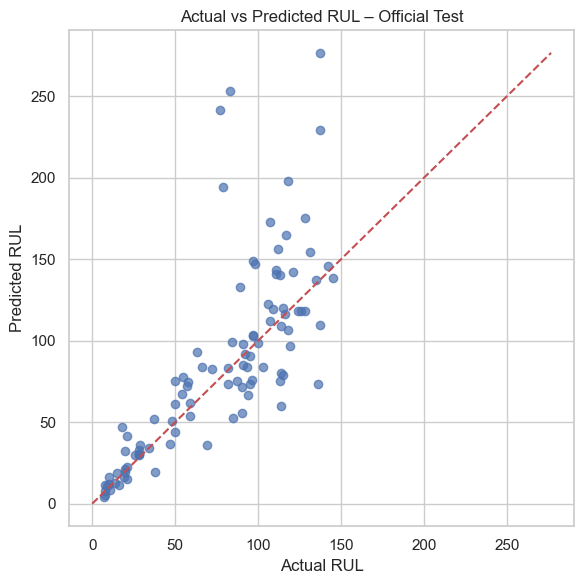

In [28]:
if best_model_name in models:
    best_feature_set = best_ml_row["Feature Set"]
    selected_features = experiment_features[best_feature_set]

    final_model = make_pipeline(
        SimpleImputer(strategy="median"),
        models[best_model_name]()
    )

    final_model.fit(
        train_features[selected_features],
        train_features["RUL"]
    )

    test_predictions = final_model.predict(
        test_last_rows[selected_features]
    )

elif best_model_name == "PyTorch MLP":
    X_train = train_features[mlp_features]
    y_train = train_features["RUL"].to_numpy(dtype=np.float32)
    X_test = test_last_rows[mlp_features]

    test_predictions = fit_mlp_for_test(
        X_train,
        y_train,
        X_test,
        best_mlp_epoch
    )

else:
    X_train_seq, y_train_seq = make_sequences(
        train_features,
        train_features["unit"].unique(),
        sequence_features,
        sequence_length
    )

    X_test_seq, _ = make_sequences(
        test_features,
        test_last_rows["unit"].to_numpy(),
        sequence_features,
        sequence_length,
        last_only=True
    )

    test_predictions = fit_gru_for_test(
        X_train_seq,
        y_train_seq,
        X_test_seq,
        best_gru_epoch
    )


test_scores = evaluate_model(
    test_last_rows["RUL"].to_numpy(),
    test_predictions
)

print("Official test results:")
display(pd.DataFrame([test_scores]).round(3))

test_predictions_df = pd.DataFrame({
    "unit": test_last_rows["unit"].to_numpy(),
    "cycle": test_last_rows["cycle"].to_numpy(),
    "actual_RUL": test_last_rows["RUL"].to_numpy(),
    "predicted_RUL": np.maximum(test_predictions, 0)
})

display(test_predictions_df.head(10))

# Inspect the engines where predictions are furthest from the actual RUL.
test_predictions_df["error"] = (
    test_predictions_df["predicted_RUL"]
    - test_predictions_df["actual_RUL"]
)

test_predictions_df["absolute_error"] = (
    test_predictions_df["error"].abs()
)

print("Largest test prediction errors:")
display(
    test_predictions_df.sort_values(
        "absolute_error", ascending=False
    ).head(10)
)

plt.figure(figsize=(6, 6))
plt.scatter(
    test_predictions_df["actual_RUL"],
    test_predictions_df["predicted_RUL"],
    alpha=0.7
)

limit = max(
    test_predictions_df["actual_RUL"].max(),
    test_predictions_df["predicted_RUL"].max()
)

plt.plot([0, limit], [0, limit], "r--")
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL – Official Test")
plt.tight_layout()
plt.show()


## 17. What I learned from the experiments

After running the notebook, I can use the validation table to answer:

1. Did rolling mean or rolling standard deviation help?
2. Did lag and difference features improve the tree models?
3. Did the MLP perform better than the tree models?
4. Did the GRU benefit from seeing a sequence of sensor readings?
5. Which model gave the best validation result?

I should use validation results for model selection and keep the official test result as the final evaluation.

**Note:** This notebook uses one engine-level validation split. For a stronger comparison, I can later repeat the experiments with multiple engine-level splits.